In [186]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import mean_squared_error, r2_score


In [187]:
DATA_FILE = "data/order_july25.csv"
PREPROCESSED_DATA_FILE = "data/preprocessed_sweet_aroma_data.csv"
NEW_CUSTOMERS_FILE = "data/new_customer25.csv"
PREDICTION_RESULT_FILE = "data/new_customer_predictions.csv"


RANDOM_STATE = 42
TEST_SIZE = 0.2

In [188]:
def load_data(file_path):
    df = pd.read_csv(file_path)
    print(f"Data loaded: {df.shape[0]} rows, {df.shape[1]} columns")
    return df

<h3>Phase 2. Data Understanding</h3>

In [189]:
# Summary statistics for the dataset.
def summarise_data(df):
    print("-" * 50)
    print("DATA SUMMARY")
    print(f"\nShape: {df.shape}")
    print(f"\nColumn types:\n{df.dtypes}")
    print(f"\nMissing values:\n{df.isnull().sum()}")
    print(f"\nMissing percentage: {df.isnull().sum().sum() / (df.shape[0] * df.shape[1]) * 100:.2f}%")
    print(f"\nTarget variable (revenue) statistics:\n{df['revenue'].describe()}")
    return df.describe()

In [190]:
def analyse_missing_values(df):
    missing_counts = df.isnull().sum()
    missing_pct = (missing_counts / len(df)) * 100

    missing_df = pd.DataFrame(
        {"Missing Count": missing_counts, "Missing %": missing_pct.round(2)}
    ).sort_values("Missing Count", ascending=False)

    rows_with_missing = df.isnull().any(axis=1).sum()
    print(
        f"\nRows with at least one missing value: {rows_with_missing} ({rows_with_missing / len(df) * 100:.2f}%)"
    )

    return missing_df

In [191]:
# Analyse correlations between numeric variables.
def analyse_correlations(df, numeric_cols):
    corr_matrix = df[numeric_cols].corr()
    print("\nCorrelation Matrix:")
    print(corr_matrix.round(3))
    return corr_matrix

In [192]:
def plot_eda_visualisations(df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax1 = axes[0]
    ax1.scatter(df["time_web"], df["revenue"], alpha=0.3, s=10, color="steelblue")

    z = np.polyfit(df["time_web"].dropna(), df.loc[df["time_web"].notna(), "revenue"], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df["time_web"].min(), df["time_web"].max(), 100)
    ax1.plot(x_line, p(x_line), "r--", linewidth=2, label="Trend line")

    corr = df["time_web"].corr(df["revenue"])
    ax1.set_xlabel("Time on Website (seconds)", fontsize=11)
    ax1.set_ylabel("Revenue (£)", fontsize=11)
    ax1.set_title(
        f"Relationship Between Website Time and Order Revenue\nCorrelation: r = {corr:.3f}", fontsize=12
    )
    ax1.legend()

    ax2 = axes[1]
    ad_labels = {1.0: "No\nAdvertisement", 2.0: "Paid\nSearch", 3.0: "Free\nSEO", 4.0: "Online\nAd"}
    df_plot = df.copy()
    df_plot["ad_channel_name"] = df_plot["ad_channel"].map(ad_labels)

    channel_order = ["No\nAdvertisement", "Paid\nSearch", "Free\nSEO", "Online\nAd"]
    sns.boxplot(x="ad_channel_name", y="revenue", data=df_plot, order=channel_order, ax=ax2)

    means = df_plot.groupby("ad_channel_name")["revenue"].mean()
    for i, channel in enumerate(channel_order):
        if channel in means.index:
            ax2.scatter(
                i, means[channel], color="red", s=50, zorder=5, marker="D", label="Mean" if i == 0 else ""
            )
            ax2.annotate(
                f"£{means[channel]:.1f}",
                (i, means[channel]),
                textcoords="offset points",
                xytext=(0, 10),
                ha="center",
                fontsize=9,
            )

    ax2.set_xlabel("Advertisement Channel", fontsize=11)
    ax2.set_ylabel("Revenue (£)", fontsize=11)
    ax2.set_title("Revenue Distribution by Advertisement Channel", fontsize=12)

    plt.tight_layout()

In [193]:
def plot_correlation_matrix(df, numeric_cols):
    corr_matrix = df[numeric_cols].corr()

    rename_map = {
        "number_past_order": "Past Orders",
        "time_web": "Time on Web",
        "voucher": "Voucher",
        "past_spend": "Past Spend",
        "revenue": "Revenue",
    }
    corr_matrix = corr_matrix.rename(index=rename_map, columns=rename_map)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Correlation Coefficient"},
        ax=ax,
    )
    plt.title("Correlation Matrix of Numeric Variables", fontsize=14, fontweight="bold", pad=15)
    plt.tight_layout()

<h3>Phase 3. Data Preparation</h3>

In [194]:
def missing_value_imputation(df):
    df_imputed = df.copy()

    logical_imputed = 0

    # If number_past_order = 0 and past_spend is missing, impute past_spend = 0
    mask1 = (df_imputed["number_past_order"] == 0) & (df_imputed["past_spend"].isna())
    df_imputed.loc[mask1, "past_spend"] = 0
    logical_imputed += mask1.sum()

    # If past_spend = 0 and number_past_order is missing, impute number_past_order = 0
    mask2 = (df_imputed["past_spend"] == 0) & (df_imputed["number_past_order"].isna())
    df_imputed.loc[mask2, "number_past_order"] = 0
    logical_imputed += mask2.sum()

    print(f"Logical imputation applied: {logical_imputed} values")

    # Numeric: median
    for col in ["past_spend", "number_past_order", "time_web"]:
        count = df_imputed[col].isna().sum()
        if count > 0:
            df_imputed[col] = df_imputed[col].fillna(df_imputed[col].median())
            print(f"  {col}: {count} values imputed with median")

    # Categorical: mode
    for col in ["voucher", "ad_channel"]:
        count = df_imputed[col].isna().sum()
        if count > 0:
            df_imputed[col] = df_imputed[col].fillna(df_imputed[col].mode()[0])
            print(f"  {col}: {count} values imputed with mode")

    return df_imputed

In [195]:
# Detect outliers using IQR method.
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

In [196]:
# Analyse outliers for multiple columns.
def analyse_outliers(df, columns):
    print("-" * 50)
    print("OUTLIER ANALYSIS")
    for col in columns:
        outliers, lb, ub = detect_outliers(df, col)
        pct = len(outliers) / len(df) * 100
        print(f"\n{col}:")
        print(f"  Bounds: [{lb:.2f}, {ub:.2f}]")
        print(f"  Outliers: {len(outliers)} ({pct:.2f}%)")
        print(f"  Range: [{df[col].min():.2f}, {df[col].max():.2f}]")

In [197]:
# Convert data types and create dummy variables.
def convert_data_types(df):
    df_converted = df.copy()

    df_converted["number_past_order"] = df_converted["number_past_order"].astype(int)
    df_converted["voucher"] = df_converted["voucher"].astype(int)
    df_converted["ad_channel"] = df_converted["ad_channel"].astype(int)

    ad_channel_labels = {1: "No_Ad", 2: "Paid_Search", 3: "Free_SEO", 4: "Online_Ad"}
    df_converted["ad_channel_name"] = df_converted["ad_channel"].map(ad_channel_labels)

    ad_dummies = pd.get_dummies(df_converted["ad_channel_name"], prefix="ad", dtype=int)
    ad_dummies = ad_dummies.drop("ad_No_Ad", axis=1)

    df_converted = pd.concat([df_converted, ad_dummies], axis=1)
    df_converted = df_converted.drop(["ad_channel", "ad_channel_name"], axis=1)

    print(f"\nDummy variables created: {list(ad_dummies.columns)}")
    print("Reference category: No_Ad (dropped)")

    return df_converted


In [198]:
# Final dataset by dropping multicollinear variable.
def prepare_final_dataset(df):
    df_final = df.drop("number_past_order", axis=1)
    print("\nDropped 'number_past_order' to address multicollinearity")
    print(f"Final columns: {list(df_final.columns)}")
    print(f"Final shape: {df_final.shape}")
    return df_final

<h3>Phase 4: Modelling</h3>

In [199]:
#  Fit a Linear Regression model using sklearn.
def fit_ols_regression(X_train, y_train):
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)

    return model, y_train_pred

In [200]:
#  Calculate standard errors for regression coefficients.
def calculate_standard_errors(X_train, y_train, y_train_pred):
    n = len(y_train)
    p = X_train.shape[1]

    X_with_const = np.column_stack([np.ones(n), X_train])
    residuals = y_train - y_train_pred

    degrees_of_freedom = n - p - 1
    mse = np.sum(residuals**2) / degrees_of_freedom

    XtX = X_with_const.T @ X_with_const
    XtX_inv = np.linalg.inv(XtX)

    variance_covariance = mse * XtX_inv
    se = np.sqrt(np.diag(variance_covariance))

    return se, mse, residuals

In [201]:
# Calculate t-statistics and p-values for hypothesis testing.
def calculate_t_statistics_pvalues(coefficients, se, n, p):
    t_stats = coefficients / se
    degrees_of_freedom = n - p - 1
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), degrees_of_freedom))
    return t_stats, p_values

In [202]:
# Calculate F-statistic for overall model significance.
def calculate_f_statistic(y_actual, y_predicted, residuals, p):
    n = len(y_actual)
    ss_reg = np.sum((y_predicted - np.mean(y_actual)) ** 2)
    ss_res = np.sum(residuals**2)
    f_stat = (ss_reg / p) / (ss_res / (n - p - 1))
    f_pvalue = 1 - stats.f.cdf(f_stat, p, n - p - 1)
    return f_stat, f_pvalue


In [203]:
def ols_regression_summary(model, feature_names, X_train, y_train, y_train_pred):
    n = len(y_train)
    p = X_train.shape[1]

    coefficients = np.concatenate([[model.intercept_], model.coef_])
    all_names = ["Intercept"] + feature_names

    se, mse, residuals = calculate_standard_errors(X_train, y_train, y_train_pred)
    t_stats, p_values = calculate_t_statistics_pvalues(coefficients, se, n, p)
    r2 = r2_score(y_train, y_train_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    f_stat, f_pvalue = calculate_f_statistic(y_train, y_train_pred, residuals, p)

    print("-" * 70)
    print("OLS REGRESSION SUMMARY")
    print(f"\nObservations: {n}")
    print(f"Predictors: {p}")
    print(f"R-squared: {r2:.4f}")
    print(f"Adjusted R-squared: {adj_r2:.4f}")
    print(f"F-statistic: {f_stat:.2f} (p-value: {f_pvalue:.2e})")
    print(f"Root MSE: {np.sqrt(mse):.4f}")

    print("COEFFICIENT ESTIMATES")
    print(f"{'Variable':<18} {'Coefficient':>12} {'Std Error':>12} {'t-stat':>10} {'p-value':>12} {'Sig':>6}")

    for i, name in enumerate(all_names):
        sig = (
            "***"
            if p_values[i] < 0.001
            else "**"
            if p_values[i] < 0.01
            else "*"
            if p_values[i] < 0.05
            else ""
        )
        print(
            f"{name:<18} {coefficients[i]:>12.4f} {se[i]:>12.4f} {t_stats[i]:>10.2f} {p_values[i]:>12.4e} {sig:>6}"
        )

    print("Significance codes: *** p<0.001, ** p<0.01, * p<0.05")

    results = {
        "coefficients": dict(zip(all_names, coefficients)),
        "std_errors": dict(zip(all_names, se)),
        "t_statistics": dict(zip(all_names, t_stats)),
        "p_values": dict(zip(all_names, p_values)),
        "r_squared": r2,
        "adj_r_squared": adj_r2,
        "f_statistic": f_stat,
        "f_pvalue": f_pvalue,
        "rmse": np.sqrt(mse),
        "residuals": residuals,
    }

    return results

In [204]:
# Run complete explanatory analysis with OLS regression.
def run_explanatory_analysis(df, feature_columns, target_column="revenue"):
    print("-" * 50)
    print("EXPLANATORY ANALYSIS (Business Question 1)")

    X = df[feature_columns]
    y = df[target_column]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

    print(f"Training set: {X_train.shape[0]} rows")
    print(f"Test set: {X_test.shape[0]} rows")

    model, y_train_pred = fit_ols_regression(X_train, y_train)
    results = ols_regression_summary(model, feature_columns, X_train, y_train.values, y_train_pred)

    return model, results, X_train, X_test, y_train, y_test

In [205]:
# Get dictionary of models to compare.
def get_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=100, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.1, max_depth=5, random_state=RANDOM_STATE
        ),
    }

In [206]:
# Evaluate model on train and test sets.
def evaluate_model(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    metrics = {
        "train_rmse": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "train_r2": r2_score(y_train, y_train_pred),
        "test_rmse": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "test_r2": r2_score(y_test, y_test_pred),
        "y_train_pred": y_train_pred,
        "y_test_pred": y_test_pred,
    }
    return metrics

In [207]:
# Perform k-fold cross-validation on a model.
def cross_validate_model(model, X_train, y_train, cv=5):
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")

    return {"cv_rmse_mean": -cv_scores.mean(), "cv_rmse_std": cv_scores.std()}

In [208]:
# Compare multiple models for predictive task.
def compare_models(X_train, y_train, X_test, y_test):
    print("-" * 50)
    print("PREDICTIVE ANALYSIS (Business Question 2)")

    models = get_models()
    results = []
    fitted_models = {}

    for name, model in models.items():
        print(f"\nTraining {name}...")

        # Train
        model.fit(X_train, y_train)
        fitted_models[name] = model

        # Evaluate
        metrics = evaluate_model(model, X_train, y_train, X_test, y_test)
        cv_results = cross_validate_model(model, X_train, y_train)

        result = {
            "Model": name,
            "Train RMSE": metrics["train_rmse"],
            "Test RMSE": metrics["test_rmse"],
            "CV RMSE": cv_results["cv_rmse_mean"],
            "CV Std": cv_results["cv_rmse_std"],
            "Train R²": metrics["train_r2"],
            "Test R²": metrics["test_r2"],
        }
        results.append(result)

        print(f"Train RMSE: {metrics['train_rmse']:.4f}")
        print(f"Test RMSE: {metrics['test_rmse']:.4f}")
        print(f"CV RMSE: {cv_results['cv_rmse_mean']:.4f} (±{cv_results['cv_rmse_std']:.4f})")

        # Check for overfitting
        overfit_ratio = metrics["test_rmse"] / metrics["train_rmse"]
        if overfit_ratio > 1.2:
            print(f"Warning: Overfitting detected (ratio: {overfit_ratio:.2f})")

    results_df = pd.DataFrame(results)

    # Print summary
    print("\n" + "-" * 70)
    print("SUMMARY COMPARISON")
    print("-" * 70)
    print(results_df.to_string(index=False))

    # Select best model
    best_idx = results_df["Test RMSE"].idxmin()
    best_model_name = results_df.loc[best_idx, "Model"]
    print(f"\n Best Model: {best_model_name} (Test RMSE: £{results_df.loc[best_idx, 'Test RMSE']:.2f})")

    return results_df, fitted_models, best_model_name

<h3>Phase 5: Model Evaluation</h3>

In [209]:
# Check OLS regression assumptions for EXPLANATORY model.
def check_ols_assumptions(model, X_train, y_train, y_train_pred, feature_names):
    print("\n" + "-" * 50)
    print("MODEL ASSUMPTIONS CHECK (EXPLANATORY MODEL)")

    residuals = y_train - y_train_pred
    n = len(y_train)
    p = X_train.shape[1]

    # 1. Linearity
    print("\n1.LINEARITY")
    print("-" * 50)
    print("Assessment: Checked via residuals vs fitted plot.")
    print("Linear model outperformed non-linear alternatives,")
    print("suggesting linear relationships are appropriate.")

    # 2. Independence
    print("\n2.INDEPENDENCE")
    print("-" * 50)
    print("Assessment: Each row represents a separate order.")
    print("Observations are assumed independent.")

    # 3. Homoscedasticity
    print("\n3.HOMOSCEDASTICITY (Constant Variance)")
    print("-" * 50)
    corr_het = np.corrcoef(np.abs(residuals), y_train_pred)[0, 1]
    print(f"Correlation |residuals| vs fitted: {corr_het:.4f}")
    if abs(corr_het) < 0.1:
        print("No strong pattern - assumption satisfied")
    else:
        print("Some heteroscedasticity may be present")

    # 4. Normality of residuals
    print("\n4.NORMALITY OF RESIDUALS")
    print("-" * 50)
    skewness = stats.skew(residuals)
    kurtosis = stats.kurtosis(residuals)
    print(f"Skewness: {skewness:.4f} (ideal: 0)")
    print(f"Kurtosis: {kurtosis:.4f} (ideal: 0)")
    if abs(skewness) < 0.5 and abs(kurtosis) < 1:
        print("Approximately normal distribution")
    else:
        print("Minor departures from normality")
    print(f"Note: With large n={n}, OLS is robust to minor departures (CLT)")

    # 5. Multicollinearity (VIF)
    print("\n5. MULTICOLLINEARITY (VIF)")
    print("-" * 50)
    print("Variable VIF Status")
    print("   " + "-" * 40)

    vif_results = {}
    for i, col in enumerate(feature_names):
        other_cols = [j for j in range(len(feature_names)) if j != i]
        X_other = X_train.iloc[:, other_cols]

        model_vif = LinearRegression()
        model_vif.fit(X_other, X_train.iloc[:, i])
        r_squared = model_vif.score(X_other, X_train.iloc[:, i])

        vif = 1 / (1 - r_squared) if r_squared < 1 else float("inf")
        vif_results[col] = vif
        status = "OK" if vif < 5 else "High"
        print(f"   {col:<20} {vif:>6.2f}     {status}")

    print("\n (VIF > 5 indicates potential multicollinearity)")

    return residuals, vif_results

In [210]:
# Check assumptions/validation for PREDICTIVE model.
def check_predictive_model_assumptions(model, X_train, y_train, X_test, y_test, model_name):
    print("\n" + "-" * 70)
    print(f"MODEL VALIDATION CHECK (PREDICTIVE MODEL: {model_name})")

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    residuals_train = y_train - y_train_pred
    residuals_test = y_test - y_test_pred

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # 1. Overfitting Check
    print("\n1. OVERFITTING CHECK")
    print("-" * 50)
    overfit_ratio = test_rmse / train_rmse
    print(f"Train RMSE: £{train_rmse:.2f}")
    print(f"Test RMSE: £{test_rmse:.2f}")
    print(f"Test/Train Ratio: {overfit_ratio:.2f}")
    if overfit_ratio < 1.2:
        print("No overfitting detected (ratio < 1.2)")
    else:
        print("Possible overfitting (ratio > 1.2)")

    # 2. Cross-Validation Stability
    print("\n2.CROSS-VALIDATION STABILITY")
    print("-" * 50)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    cv_rmse = -cv_scores.mean()
    cv_std = cv_scores.std()
    print(f"5-Fold CV RMSE: £{cv_rmse:.2f} (±{cv_std:.2f})")
    print(f"CV Scores: {[-s for s in cv_scores.round(2)]}")
    if cv_std < 0.5:
        print("Stable performance across folds")
    else:
        print("High variance across folds")

    # 3. Residual Analysis
    print("\n3. RESIDUAL ANALYSIS (Test Set)")
    print("-" * 50)
    print(f"Mean residual: £{residuals_test.mean():.2f} (ideal: 0)")
    print(f"Std of residuals: £{residuals_test.std():.2f}")
    print(f"Skewness: {stats.skew(residuals_test):.3f}")

    # 4. Prediction Range Check
    print("\n4. PREDICTION VALIDITY")
    print("-" * 50)
    print(f"Actual revenue range: £{y_test.min():.0f} - £{y_test.max():.0f}")
    print(f"Predicted range: £{y_test_pred.min():.0f} - £{y_test_pred.max():.0f}")

    # Check for impossible predictions
    negative_preds = (y_test_pred < 0).sum()
    if negative_preds > 0:
        print(f"{negative_preds} negative predictions detected")
    else:
        print("All predictions are valid (non-negative)")

    return residuals_test

In [211]:
# Generate diagnostic plots for model validation.
def plot_diagnostic_plots(y_train, y_train_pred, residuals, title_prefix=""):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    # 1. Residuals vs Fitted
    ax1 = axes[0, 0]
    ax1.scatter(y_train_pred, residuals, alpha=0.3, s=10, color="steelblue")
    ax1.axhline(y=0, color="red", linestyle="--", linewidth=1.5)
    ax1.set_xlabel("Fitted Values (£)")
    ax1.set_ylabel("Residuals (£)")
    ax1.set_title("Residuals vs Fitted Values\n(Checking Linearity & Homoscedasticity)")

    # 2. Q-Q Plot
    ax2 = axes[0, 1]
    stats.probplot(residuals, dist="norm", plot=ax2)
    ax2.set_title("Q-Q Plot of Residuals\n(Checking Normality)")

    # 3. Histogram of Residuals
    ax3 = axes[1, 0]
    ax3.hist(residuals, bins=50, color="steelblue", edgecolor="black", alpha=0.7, density=True)
    xmin, xmax = ax3.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, residuals.mean(), residuals.std())
    ax3.plot(x, p, "r-", linewidth=2, label="Normal Distribution")
    ax3.set_xlabel("Residuals (£)")
    ax3.set_ylabel("Density")
    ax3.set_title("Distribution of Residuals")
    ax3.legend()

    # 4. Scale-Location Plot
    ax4 = axes[1, 1]
    standardized_residuals = residuals / residuals.std()
    ax4.scatter(y_train_pred, np.sqrt(np.abs(standardized_residuals)), alpha=0.3, s=10, color="steelblue")
    ax4.set_xlabel("Fitted Values (£)")
    ax4.set_ylabel("√|Standardized Residuals|")
    ax4.set_title("Scale-Location Plot\n(Checking Homoscedasticity)")

    plt.tight_layout()

In [212]:
# Preprocess new customer data with same transformations as training data.
def preprocess_new_customers(new_customers):
    df = new_customers.copy()

    ad_channel_labels = {1: "No_Ad", 2: "Paid_Search", 3: "Free_SEO", 4: "Online_Ad"}
    df["ad_channel_name"] = df["ad_channel"].map(ad_channel_labels)

    ad_dummies = pd.get_dummies(df["ad_channel_name"], prefix="ad", dtype=int)

    # Ensure all columns exist
    for col in ["ad_Free_SEO", "ad_Online_Ad", "ad_Paid_Search"]:
        if col not in ad_dummies.columns:
            ad_dummies[col] = 0

    ad_dummies = ad_dummies[["ad_Free_SEO", "ad_Online_Ad", "ad_Paid_Search"]]
    df = pd.concat([df, ad_dummies], axis=1)
    df = df.drop(["ad_channel", "ad_channel_name", "number_past_order"], axis=1)

    return df

In [213]:
def predict_new_customers(model, df_train, new_customers, feature_columns):
    print("-" * 50)
    print("PREDICTIONS FOR NEW CUSTOMERS")

    new_customers_processed = preprocess_new_customers(new_customers)
    X_new = new_customers_processed[feature_columns]

    predictions = model.predict(X_new)
    new_customers["predicted_revenue"] = predictions.round(2)

    print(f"\nPredictions generated for {len(new_customers)} customers")
    print("\nSummary Statistics:")
    print(f"Mean: £{predictions.mean():.2f}")
    print(f"Median: £{np.median(predictions):.2f}")
    print(f"Min: £{predictions.min():.2f}")
    print(f"Max: £{predictions.max():.2f}")

    print("\n" + "-" * 50)
    print("PREDICTION RESULTS")
    output = new_customers[["order", "predicted_revenue"]].copy()
    output.columns = ["Order", "Predicted Revenue (£)"]
    print(output.to_string(index=False))

    return new_customers, predictions



----------------------------------------------------------------------
PHASE 1: DATA LOADING
Data loaded: 10000 rows, 6 columns

----------------------------------------------------------------------
PHASE 2: DATA UNDERSTANDING
--------------------------------------------------
DATA SUMMARY

Shape: (10000, 6)

Column types:
number_past_order    float64
time_web             float64
voucher              float64
past_spend           float64
ad_channel           float64
revenue              float64
dtype: object

Missing values:
number_past_order    116
time_web             103
voucher              134
past_spend           124
ad_channel           118
revenue                0
dtype: int64

Missing percentage: 0.99%

Target variable (revenue) statistics:
count    10000.000000
mean        55.458100
std         13.276516
min          4.000000
25%         47.000000
50%         56.000000
75%         64.000000
max        106.000000
Name: revenue, dtype: float64

Rows with at least one missing v

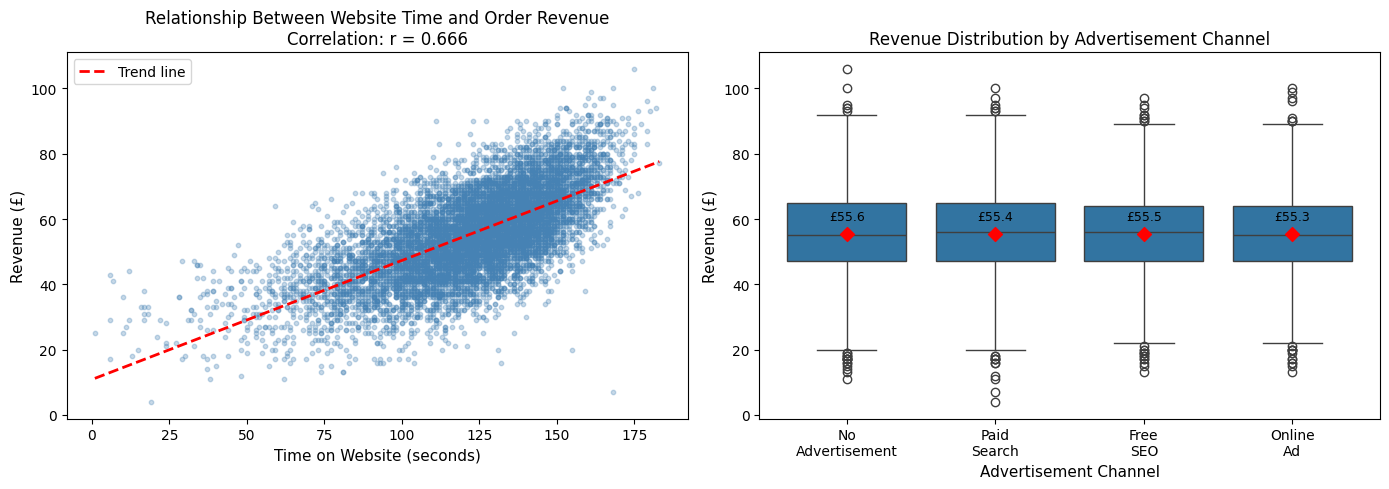

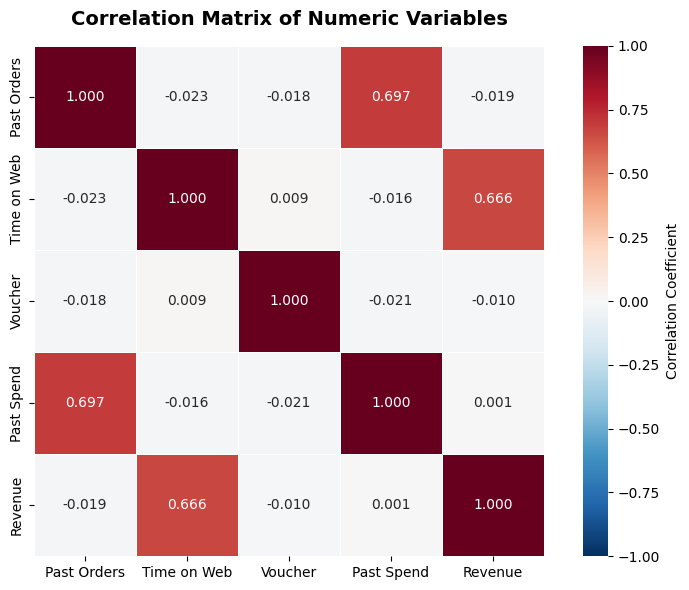

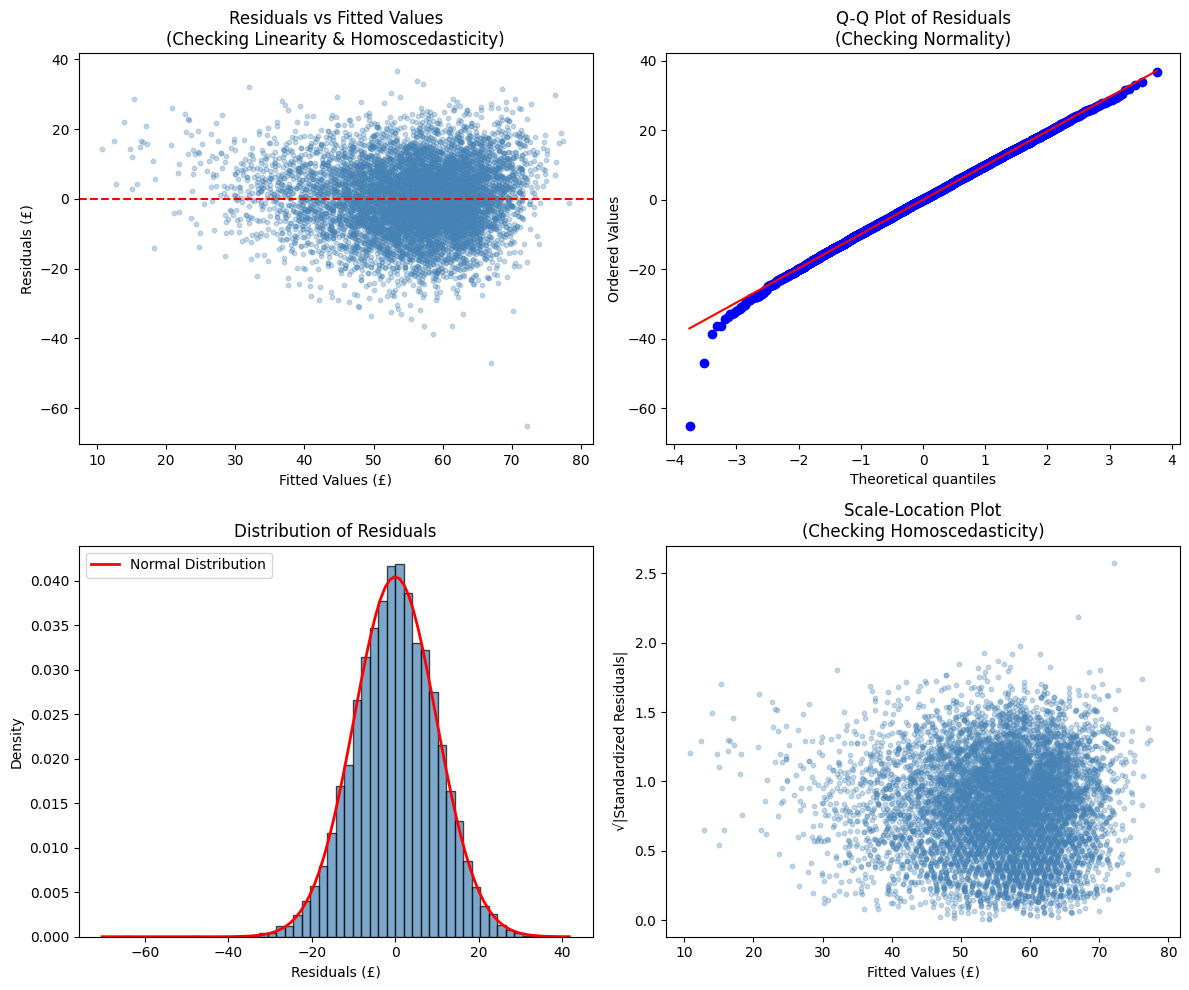

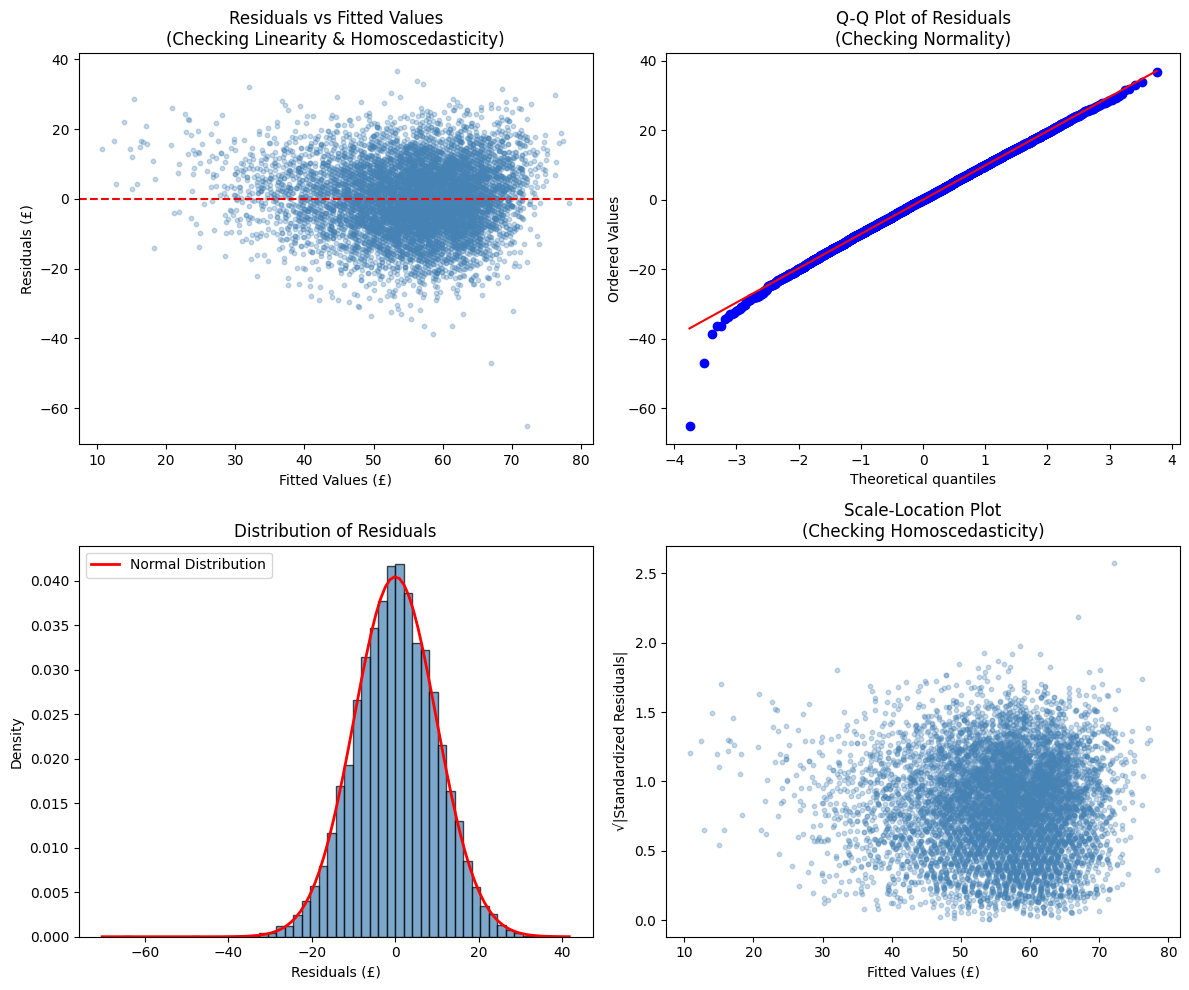

In [214]:
def main():
    # Phase 1: Load Data
    print("\n" + "-" * 70)
    print("PHASE 1: DATA LOADING")
    print("=" * 70)
    df = load_data(DATA_FILE)

    # Phase 2: Data Understanding
    print("\n" + "-" * 70)
    print("PHASE 2: DATA UNDERSTANDING")
    summarise_data(df)
    missing_df = analyse_missing_values(df)
    print("\nMissing Values Summary:")
    print(missing_df)

    numeric_cols = ["number_past_order", "time_web", "voucher", "past_spend", "revenue"]
    analyse_correlations(df, numeric_cols)

    # Visualisations
    plot_eda_visualisations(df)
    plot_correlation_matrix(df, numeric_cols)

    # Phase 3: Data Preparation
    print("\n" + "-" * 70)
    print("PHASE 3: DATA PREPARATION")

    df_imputed = missing_value_imputation(df)
    analyse_outliers(df_imputed, ["revenue", "time_web", "past_spend", "number_past_order"])
    df_converted = convert_data_types(df_imputed)
    df_final = prepare_final_dataset(df_converted)

    df_final.to_csv(PREPROCESSED_DATA_FILE, index=False)
    print(f"\nPreprocessed data saved to: {PREPROCESSED_DATA_FILE}")

    # Phase 4: Modelling
    feature_columns = ["time_web", "past_spend", "voucher", "ad_Free_SEO", "ad_Online_Ad", "ad_Paid_Search"]

    # Explanatory Analysis (Business Question 1)
    model_ols, ols_results, X_train, X_test, y_train, y_test = run_explanatory_analysis(
        df_final, feature_columns
    )

    # Predictive Analysis (Business Question 2)
    results_df, fitted_models, best_model_name = compare_models(X_train, y_train, X_test, y_test)

    # Phase 5: Model Assumptions
    print("\n" + "-" * 70)
    print("PHASE 5: MODEL VALIDATION")

    # Check OLS assumptions (Explanatory)
    y_train_pred = model_ols.predict(X_train)
    residuals, vif_results = check_ols_assumptions(model_ols, X_train, y_train, y_train_pred, feature_columns)
    plot_diagnostic_plots(y_train.values, y_train_pred, residuals, "explanatory_")

    # Check predictive model validation
    best_model = fitted_models[best_model_name]
    check_predictive_model_assumptions(best_model, X_train, y_train, X_test, y_test, best_model_name)

    y_train_pred_best = best_model.predict(X_train)
    residuals_pred = y_train.values - y_train_pred_best
    plot_diagnostic_plots(y_train.values, y_train_pred_best, residuals_pred, "predictive_")

    # Phase 6: New Customer Predictions
    print("\n" + "-" * 70)
    print("PHASE 6: NEW CUSTOMER PREDICTIONS")

    new_customers = pd.read_csv(NEW_CUSTOMERS_FILE)
    final_model = LinearRegression()
    final_model.fit(df_final[feature_columns], df_final["revenue"])

    new_customers_results, predictions = predict_new_customers(
        final_model, df_final, new_customers, feature_columns
    )

    output_df = new_customers_results[["order", "predicted_revenue"]].copy()
    output_df.columns = ["Order", "Predicted Revenue (£)"]
    output_df.to_csv(PREDICTION_RESULT_FILE, index=False)
    print(f"\nPredictions saved to: {PREDICTION_RESULT_FILE}")


main()